# Rainfall infiltration and soil water redistribution

**Numerical Methods for the Geosciences**

Compare MGAR and Richards 1D during rainfall and redistribution. Assess infiltration and moisture profiles, sensitivity to numerical choices, and computational cost. Use the supplied solvers.

The case is a **vertical soil column beneath a level ground surface**. Loam is a soil texture with a mixture of sand, silt and clay. Read the accompanying guide for the model background and literature. You need Python 3, NumPy, pandas, Matplotlib and Jupyter.

## Imports and soil parameters

Load the libraries, define rainfall helpers and set up the soil parameters.

In [2]:
# Load the libraries, define rainfall helpers and set up the soil parameters.
import numpy as np

import pandas as pd
import matplotlib.pyplot as plt

def mmph_to_mps(x_mmph):
    return np.asarray(x_mmph, dtype=float) / 1000.0 / 3600.0

def mps_to_mmph(x_mps):
    return np.asarray(x_mps, dtype=float) * 3600.0 * 1000.0

def build_rain_grid(rain, rain_mode, t_end, dt, rain_dt=None):
    dt = float(dt)
    rain_mode = str(rain_mode).lower()

    if rain_mode == 'steady':
        if not np.isscalar(rain):
            raise ValueError("With rain_mode='steady', rain must be scalar.")
        if t_end is None:
            raise ValueError('t_end is required.')
        n_float = float(t_end) / dt
        n_steps = int(round(n_float))
        if not np.isclose(n_float, n_steps):
            raise ValueError('t_end must be an exact multiple of dt.')
        t = np.arange(n_steps + 1, dtype=float) * dt
        rain_step = np.full(n_steps, max(float(rain), 0.0))

    elif rain_mode == 'unsteady':
        rain = np.asarray(rain, dtype=float)
        if rain.ndim != 1 or len(rain) == 0:
            raise ValueError('rain must be a non-empty 1-D vector.')
        if rain_dt is None:
            raise ValueError('rain_dt is required for unsteady rainfall.')
        ratio = float(rain_dt) / dt
        steps_per_rain = int(round(ratio))
        if not np.isclose(ratio, steps_per_rain):
            raise ValueError('rain_dt must be an exact multiple of dt.')
        rain_step = np.repeat(np.maximum(rain, 0.0), steps_per_rain)
        t = np.arange(len(rain_step) + 1, dtype=float) * dt
        expected = len(rain) * float(rain_dt)
        if t_end is not None and not np.isclose(float(t_end), expected):
            raise ValueError('t_end must equal len(rain)*rain_dt.')
    else:
        raise ValueError("rain_mode must be 'steady' or 'unsteady'.")

    rain_ts = np.r_[rain_step, rain_step[-1]] if len(rain_step) else np.zeros_like(t)
    return t, rain_step, rain_ts

GOWDISH_SOILS = {
    "sand": {
        "theta_s": 0.417, "theta_r": 0.020, "theta_i": 0.033,
        "hb_cm": 7.26, "lambda_bc": 0.694, "Ks_cm_h": 23.56,
        "Sav_cm": 9.62, "FC": 0.048,
        "alpha_cm": 0.1310, "n_vg": 82.5535, "m_vg": 0.0085,
        "A_cm_h": 30.0, "B_cm_h": 31.0,
    },
    "sandy_loam": {
        "theta_s": 0.412, "theta_r": 0.041, "theta_i": 0.095,
        "hb_cm": 14.66, "lambda_bc": 0.378, "Ks_cm_h": 2.18,
        "Sav_cm": 21.53, "FC": 0.155,
        "alpha_cm": 0.0608, "n_vg": 66.4880, "m_vg": 0.0059,
        "A_cm_h": 7.0, "B_cm_h": 8.0,
    },
    "loam": {
        "theta_s": 0.434, "theta_r": 0.027, "theta_i": 0.117,
        "hb_cm": 11.15, "lambda_bc": 0.252, "Ks_cm_h": 1.32,
        "Sav_cm": 17.50, "FC": 0.200,
        "alpha_cm": 0.0804, "n_vg": 48.2744, "m_vg": 0.0054,
        "A_cm_h": 4.0, "B_cm_h": 5.0,
    },
    "silt_loam": {
        "theta_s": 0.486, "theta_r": 0.015, "theta_i": 0.133,
        "hb_cm": 20.79, "lambda_bc": 0.234, "Ks_cm_h": 0.68,
        "Sav_cm": 32.96, "FC": 0.261,
        "alpha_cm": 0.0448, "n_vg": 72.0750, "m_vg": 0.0033,
        "A_cm_h": 4.0, "B_cm_h": 5.0,
    },
    "clay": {
        "theta_s": 0.385, "theta_r": 0.090, "theta_i": 0.272,
        "hb_cm": 37.30, "lambda_bc": 0.165, "Ks_cm_h": 0.06,
        "Sav_cm": 62.25, "FC": 0.296,
        "alpha_cm": 0.0259, "n_vg": 126.4091, "m_vg": 0.0013,
        "A_cm_h": 1.0, "B_cm_h": 2.0,
    },
}

def enrich_soil(s):
    s = dict(s)
    s["Ks_mmph"] = s["Ks_cm_h"] * 10.0
    s["Ks_mps"] = mmph_to_mps(s["Ks_mmph"])
    s["Sav_m"] = s["Sav_cm"] / 100.0
    s["Se0"] = (
        (s["theta_i"] - s["theta_r"])
        / (s["theta_s"] - s["theta_r"])
    )
    s["dtheta"] = s["theta_s"] - s["theta_i"]
    return s

GOWDISH_SOILS = {
    k: enrich_soil(v)
    for k, v in GOWDISH_SOILS.items()
}

## Shared hydraulic functions

Define Brooks–Corey conductivity, the MGAR capillary drive and the redistribution correction.

In [3]:
# Define Brooks–Corey conductivity, the MGAR capillary drive and the redistribution correction.
def bc_effective_saturation(theta, soil):
    return np.clip(
        (np.asarray(theta) - soil["theta_r"])
        / (soil["theta_s"] - soil["theta_r"]),
        1e-12,
        1.0,
    )

def bc_K(theta, soil):
    Se = bc_effective_saturation(theta, soil)
    return soil["Ks_mps"] * Se ** (
        3.0 + 2.0 / soil["lambda_bc"]
    )

def bc_G(theta_low, theta_high, soil):
    Ta = float(bc_effective_saturation(theta_low, soil))
    Tb = float(bc_effective_saturation(theta_high, soil))
    p = 3.0 + 1.0 / soil["lambda_bc"]
    den = 1.0 - Ta**p

    if abs(den) < 1e-14:
        return 0.0

    return soil["Sav_m"] * (
        (Tb**p - Ta**p) / den
    )

def mgar_gamma(Ks_mmph, NR, TR_h):
    if TR_h <= 0.0:
        return 0.0

    b = [4.2952, 0.0020, -14.0032]
    c = [154.6101, -0.0010, -61.5429]
    d = [-1.0, 0.5, -1.0]

    aa = []
    for i in range(1, 4):
        base = b[i-1] + c[i-1] * Ks_mmph ** d[i-1]
        aa.append(base ** ((-1) ** i))

    return float(
        aa[0]
        + aa[1] * np.log(TR_h)
        + aa[2] / float(NR)
    )

## Richards 1D solver

Define van Genuchten retention and Brooks–Corey conductivity, then solve vertical flow with Richards. Van Genuchten maps pressure head to water content. Brooks–Corey maps effective saturation to conductivity. The two laws supply different parts of the same solver.

Gowdish and Muñoz-Carpena (2009) used Brooks–Corey for MGAR conductivity and capillary drive, and paired van Genuchten retention with Brooks–Corey conductivity in their Richards benchmark. They report that this pairing allowed convergence across all 11 soil textures in their tests, especially the coarser soils. They fitted van Genuchten parameters to the Brooks–Corey retention curves and checked that the resulting hydraulic functions were similar. This project uses the same pairing for its main Richards reference. Van Genuchten also converts the raw MGAR water-content profile to pressure head when restarting Richards. A Richards run with Brooks–Corey retention and conductivity is an optional sensitivity test. [Original paper, equations 3–4 and Tables 1–2](https://doi.org/10.2136/vzj2008.0049).

In [4]:
# Define van Genuchten retention and Brooks–Corey conductivity, then solve vertical flow with Richards.
def _vg_theta_C_K(h, alpha_m, n, m, theta_r, theta_s, Ks, lambda_bc):
    h = np.asarray(h, dtype=float)

    Se = np.ones_like(h)
    C = np.zeros_like(h)

    neg = h < 0.0

    if np.any(neg):
        x = np.maximum(-h[neg], 1e-300)

        logx = np.log(x)
        loga = np.log(max(float(alpha_m), 1e-300))


        log_axn = n * (loga + logx)


        log_one_plus_axn = np.logaddexp(0.0, log_axn)

        log_Se = -m * log_one_plus_axn
        Se_neg = np.exp(np.clip(log_Se, -745.0, 0.0))

        Se[neg] = Se_neg



        log_dSe = (
            np.log(max(float(m*n), 1e-300))
            + log_axn
            - logx
            - (m + 1.0) * log_one_plus_axn
        )

        dSe_dh = np.exp(np.clip(log_dSe, -745.0, 700.0))
        C[neg] = (theta_s - theta_r) * dSe_dh

    Se = np.clip(Se, 1e-12, 1.0)
    theta = theta_r + (theta_s - theta_r) * Se

    lam = float(lambda_bc)
    if lam <= 0:
        raise ValueError("lambda_bc must be positive.")

    Kr = Se ** (3.0 + 2.0 / lam)
    K = Ks * np.clip(Kr, 0.0, 1.0)

    return theta, C, K, Se

def _thomas(lower, diag, upper, rhs):
    n = len(diag)

    cp = np.empty(n - 1, dtype=float)
    dp = np.empty(n, dtype=float)

    den = diag[0]
    if abs(den) < 1e-30:
        den = np.copysign(1e-30, den if den != 0 else 1.0)

    cp[0] = upper[0] / den
    dp[0] = rhs[0] / den

    for i in range(1, n):
        den = diag[i] - lower[i - 1] * cp[i - 1]

        if abs(den) < 1e-30:
            den = np.copysign(1e-30, den if den != 0 else 1.0)

        if i < n - 1:
            cp[i] = upper[i] / den

        dp[i] = (
            rhs[i] - lower[i - 1] * dp[i - 1]
        ) / den

    x = np.empty(n, dtype=float)
    x[-1] = dp[-1]

    for i in range(n - 2, -1, -1):
        x[i] = dp[i] - cp[i] * x[i + 1]

    return x

def _K_face(K):
    K = np.asarray(K, dtype=float)
    return 0.5 * (K[:-1] + K[1:])

def _richards_picard_step(
    h_old, dt, q_rain_normal, dz, cosg,
    alpha_m, n_vg, m_vg, theta_r, theta_s, Ks, ell_vg,
    boundary="flux",
    max_iter=100,
    tol_h=1e-6,
    relaxation=0.65,
):
    pars = (
        alpha_m, n_vg, m_vg,
        theta_r, theta_s, Ks, ell_vg
    )

    theta_old = _vg_theta_C_K(h_old, *pars)[0]

    h_it = h_old.copy()
    N = len(h_it)
    err = np.inf

    for it in range(int(max_iter)):
        theta_it, C, K, _ = _vg_theta_C_K(
            h_it, *pars
        )

        Ceff = np.maximum(C, 1e-10)
        Kface = _K_face(K)

        lower = np.zeros(N - 1)
        diag = np.zeros(N)
        upper = np.zeros(N - 1)
        rhs = np.zeros(N)


        KR = Kface[0]

        if boundary == "flux":

            diag[0] = (
                Ceff[0] / dt
                + KR / dz**2
            )

            upper[0] = -KR / dz**2

            rhs[0] = (
                Ceff[0] / dt * h_it[0]
                - (theta_it[0] - theta_old[0]) / dt
                + (q_rain_normal - KR * cosg) / dz
            )

        elif boundary == "head":


            Kb = 0.5 * (Ks + K[0])

            diag[0] = (
                Ceff[0] / dt
                + (2.0 * Kb + KR) / dz**2
            )

            upper[0] = -KR / dz**2

            rhs[0] = (
                Ceff[0] / dt * h_it[0]
                - (theta_it[0] - theta_old[0]) / dt
                + (Kb - KR) * cosg / dz
            )

        else:
            raise ValueError(
                "boundary must be 'flux' or 'head'."
            )


        if N > 2:
            KL = Kface[:-1]
            KRv = Kface[1:]

            lower[:N-2] = -KL / dz**2

            diag[1:N-1] = (
                Ceff[1:N-1] / dt
                + (KL + KRv) / dz**2
            )

            upper[1:] = -KRv / dz**2

            rhs[1:N-1] = (
                Ceff[1:N-1] / dt * h_it[1:N-1]
                - (theta_it[1:N-1] - theta_old[1:N-1]) / dt
                + (KL - KRv) * cosg / dz
            )


        KLb = Kface[-1]

        lower[-1] = -KLb / dz**2

        diag[-1] = (
            Ceff[-1] / dt
            + KLb / dz**2
        )

        rhs[-1] = (
            Ceff[-1] / dt * h_it[-1]
            - (theta_it[-1] - theta_old[-1]) / dt
            + KLb * cosg / dz
        )

        h_candidate = _thomas(
            lower, diag, upper, rhs
        )

        h_new = (
            relaxation * h_candidate
            + (1.0 - relaxation) * h_it
        )



        err_full = float(
            np.max(np.abs(h_candidate - h_it))
        )

        h_it = h_new
        err = err_full

        if err_full < tol_h:
            break

    theta_new, _, K_new, _ = _vg_theta_C_K(
        h_it, *pars
    )

    converged = err < tol_h

    if boundary == "flux":
        q_top = float(q_rain_normal)



        Kb = 0.5 * (Ks + K_new[0])

        h_surface_est = float(
            h_it[0]
            + 0.5 * dz
            * (q_rain_normal / max(Kb, 1e-30) - cosg)
        )

    else:

        Kb = 0.5 * (Ks + K_new[0])

        q_top = float(
            Kb * (
                cosg
                - 2.0 * h_it[0] / dz
            )
        )

        h_surface_est = 0.0

    return {
        "h": h_it,
        "theta": theta_new,
        "q_top": q_top,
        "h_surface": h_surface_est,
        "converged": converged,
        "iterations": it + 1,
        "error": err,
    }

def _richards_atmospheric_substep(
    h_old,
    dt_sub,
    qn,
    dz,
    cosg,
    alpha_m,
    n_vg,
    m_vg,
    theta_r,
    theta_s,
    Ks,
    ell_vg,
    max_iter,
    tol_h,
    prefer_head=False,
    release_hysteresis=0.01,
):

    if qn <= 0.0:
        sol = _richards_picard_step(
            h_old=h_old,
            dt=dt_sub,
            q_rain_normal=0.0,
            dz=dz,
            cosg=cosg,
            alpha_m=alpha_m,
            n_vg=n_vg,
            m_vg=m_vg,
            theta_r=theta_r,
            theta_s=theta_s,
            Ks=Ks,
            ell_vg=ell_vg,
            boundary="flux",
            max_iter=max_iter,
            tol_h=tol_h,
            relaxation=0.65,
        )
        return sol, "flux", False





    if prefer_head:
        sol_head = _richards_picard_step(
            h_old=h_old,
            dt=dt_sub,
            q_rain_normal=qn,
            dz=dz,
            cosg=cosg,
            alpha_m=alpha_m,
            n_vg=n_vg,
            m_vg=m_vg,
            theta_r=theta_r,
            theta_s=theta_s,
            Ks=Ks,
            ell_vg=ell_vg,
            boundary="head",
            max_iter=max_iter,
            tol_h=tol_h,
            relaxation=0.55,
        )

        if sol_head["q_top"] <= qn * (1.0 + release_hysteresis):
            return sol_head, "head", True


        sol_flux = _richards_picard_step(
            h_old=h_old,
            dt=dt_sub,
            q_rain_normal=qn,
            dz=dz,
            cosg=cosg,
            alpha_m=alpha_m,
            n_vg=n_vg,
            m_vg=m_vg,
            theta_r=theta_r,
            theta_s=theta_s,
            Ks=Ks,
            ell_vg=ell_vg,
            boundary="flux",
            max_iter=max_iter,
            tol_h=tol_h,
            relaxation=0.65,
        )
        return sol_flux, "flux", False




    sol_flux = _richards_picard_step(
        h_old=h_old,
        dt=dt_sub,
        q_rain_normal=qn,
        dz=dz,
        cosg=cosg,
        alpha_m=alpha_m,
        n_vg=n_vg,
        m_vg=m_vg,
        theta_r=theta_r,
        theta_s=theta_s,
        Ks=Ks,
        ell_vg=ell_vg,
        boundary="flux",
        max_iter=max_iter,
        tol_h=tol_h,
        relaxation=0.65,
    )

    if sol_flux["h_surface"] <= 1e-8:
        return sol_flux, "flux", False


    sol_head = _richards_picard_step(
        h_old=h_old,
        dt=dt_sub,
        q_rain_normal=qn,
        dz=dz,
        cosg=cosg,
        alpha_m=alpha_m,
        n_vg=n_vg,
        m_vg=m_vg,
        theta_r=theta_r,
        theta_s=theta_s,
        Ks=Ks,
        ell_vg=ell_vg,
        boundary="head",
        max_iter=max_iter,
        tol_h=tol_h,
        relaxation=0.55,
    )

    if sol_head["q_top"] < qn:
        return sol_head, "head", True

    return sol_flux, "flux", False

def _richards_adaptive_interval(
    h_start,
    dt_total,
    qn,
    dz,
    cosg,
    alpha_m,
    n_vg,
    m_vg,
    theta_r,
    theta_s,
    Ks,
    ell_vg,
    max_iter,
    tol_h,
    ponding_state,
    dt_max=2.5,
    dt_min=0.02,
    growth=1.5,
    easy_iter=12,
    max_retries=20,
):
    h = h_start.copy()
    remaining = float(dt_total)
    dt_try = min(float(dt_max), remaining)

    I_increment = 0.0
    runoff_increment_vertical = 0.0
    total_iterations = 0
    accepted_substeps = 0
    rejected_attempts = 0
    min_dt_used = np.inf
    any_head = False
    hs_last = np.nan
    pond_state = bool(ponding_state)

    eps_time = 1e-12 * max(1.0, dt_total)

    while remaining > eps_time:
        dt_try = min(dt_try, remaining)
        retries = 0

        while True:
            h_trial_start = h.copy()
            pond_trial_start = pond_state

            sol, boundary, pond_trial_new = _richards_atmospheric_substep(
                h_old=h_trial_start,
                dt_sub=dt_try,
                qn=qn,
                dz=dz,
                cosg=cosg,
                alpha_m=alpha_m,
                n_vg=n_vg,
                m_vg=m_vg,
                theta_r=theta_r,
                theta_s=theta_s,
                Ks=Ks,
                ell_vg=ell_vg,
                max_iter=max_iter,
                tol_h=tol_h,
                prefer_head=pond_trial_start,
                release_hysteresis=0.01,
            )

            total_iterations += sol["iterations"]

            if sol["converged"]:
                h = sol["h"].copy()
                pond_state = bool(pond_trial_new)

                q_top = float(np.clip(sol["q_top"], 0.0, qn))
                excess_normal = max(qn - q_top, 0.0)

                I_increment += q_top * dt_try
                runoff_increment_vertical += (
                    excess_normal / max(cosg, 1e-12) * dt_try
                )

                any_head = any_head or (
                    boundary == "head" and excess_normal > 1e-15
                )
                hs_last = sol["h_surface"]

                remaining -= dt_try
                accepted_substeps += 1
                min_dt_used = min(min_dt_used, dt_try)

                if sol["iterations"] <= easy_iter:
                    dt_try = min(dt_try * growth, dt_max)

                break

            rejected_attempts += 1
            retries += 1
            dt_new = 0.5 * dt_try

            if dt_new < dt_min or retries > max_retries:
                raise RuntimeError(
                    "Richards failed to converge with adaptive time stepping. "
                    f"dt={dt_try:.6g} s, dt_new={dt_new:.6g} s, "
                    f"dt_min={dt_min:.6g} s, remaining={remaining:.6g} s, "
                    f"Picard error={sol['error']:.6e}, "
                    f"iterations={sol['iterations']}"
                )

            dt_try = dt_new

    if not np.isfinite(min_dt_used):
        min_dt_used = dt_total

    return {
        "h": h,
        "ponding_state": pond_state,
        "I_increment": I_increment,
        "runoff_increment_vertical": runoff_increment_vertical,
        "iterations": total_iterations,
        "accepted_substeps": accepted_substeps,
        "rejected_attempts": rejected_attempts,
        "min_dt_used": min_dt_used,
        "any_head": any_head,
        "h_surface": hs_last,
    }

def richards_gowdish_slope(
    rain, Ks, theta_r, theta_s,
    alpha_vg_cm, n_vg, m_vg, ell_vg, Se0,
    t_end, dt, gamma_deg,
    rain_mode="steady", rain_dt=None,
    depth=2.0, dz=0.04,
    max_iter=150, tol_h=1e-5,
    front_fraction=0.05,
    internal_dt_max=2.5,
    internal_dt_min=0.002,
    theta_initial=None,
):
    # transform degrees to radians
    gamma = np.deg2rad(float(gamma_deg))
    cosg = float(np.cos(gamma))
    if cosg <= 0.0:
        raise ValueError("gamma_deg must be below 90 degrees.")

    # alpha cm -> m
    alpha_m = float(alpha_vg_cm) * 100.0
    Se0 = float(np.clip(Se0, 1e-6, 1.0 - 1e-8))

    # the initial water content and the difference to saturation
    theta_i = theta_r + Se0 * (theta_s - theta_r)
    dtheta = theta_s - theta_i

    # compute the initial hydraulic head
    h_init = -(
        (Se0**(-1.0/m_vg) - 1.0)**(1.0/n_vg)
    ) / alpha_m

    # build the time grid and the rainfall time series
    t, rain_step, rain_ts = build_rain_grid(
        rain=rain,
        rain_mode=rain_mode,
        t_end=t_end,
        dt=dt,
        rain_dt=rain_dt,
    )

    # build the vertical grid and initialize the state variables
    depth = float(depth)
    dz_target = float(dz)
    N = max(20, int(np.ceil(depth / dz_target)))
    dz = depth / N
    z = (np.arange(N, dtype=float) + 0.5) * dz

    # initialize the pressure head profile
    h = np.full(N, h_init, dtype=float)
    if theta_initial is not None:
        initial = np.asarray(theta_initial, dtype=float)
        if initial.shape != (N,) or np.any(~np.isfinite(initial)) or np.any(initial <= theta_r) or np.any(initial > theta_s):
            raise ValueError("The initial profile must match the grid and lie in the physical range.")
        se = (initial - theta_r) / (theta_s - theta_r)
        h = -(np.expm1(-np.log(se) / m_vg)**(1/n_vg)) / alpha_m

    nt = len(t)

    I = np.zeros(nt)
    R = np.zeros(nt)
    P = np.zeros(nt)
    i_rate = np.zeros(nt)
    ro_rate = np.zeros(nt)
    ponded = np.zeros(nt, dtype=bool)
    h_surface = np.full(nt, h_init)
    iterations = np.zeros(nt, dtype=int)

    theta_profiles = np.empty((nt, N), dtype=float)
    theta_profiles[0] = _vg_theta_C_K(
        h, alpha_m, n_vg, m_vg,
        theta_r, theta_s, Ks, ell_vg
    )[0]

    storage = np.zeros(nt)
    storage[0] = np.sum(theta_profiles[0]) * dz

    # initialize the storage and other variables
    nonconverged_steps = 0
    rejected_attempts_total = 0
    min_adaptive_dt = np.inf
    max_substeps_used = 1
    ponding_state = False

    for k in range(1, nt):
        q_vertical = float(rain_step[k - 1])
        qn = max(q_vertical * cosg, 0.0)

        P[k] = P[k - 1] + q_vertical * dt

        adaptive = _richards_adaptive_interval(
            h_start=h,
            dt_total=dt,
            qn=qn,
            dz=dz,
            cosg=cosg,
            alpha_m=alpha_m,
            n_vg=n_vg,
            m_vg=m_vg,
            theta_r=theta_r,
            theta_s=theta_s,
            Ks=Ks,
            ell_vg=ell_vg,
            max_iter=max_iter,
            tol_h=tol_h,
            ponding_state=ponding_state,
            dt_max=internal_dt_max,
            dt_min=internal_dt_min,
            growth=1.5,
            easy_iter=12,
            max_retries=20,
        )

        h = adaptive["h"]
        ponding_state = adaptive["ponding_state"]

        I_step = adaptive["I_increment"]
        R_step_vertical = adaptive["runoff_increment_vertical"]
        iter_step = adaptive["iterations"]
        any_head = adaptive["any_head"]
        hs_last = adaptive["h_surface"]

        rejected_attempts_total += adaptive["rejected_attempts"]
        min_adaptive_dt = min(
            min_adaptive_dt,
            adaptive["min_dt_used"]
        )
        max_substeps_used = max(
            max_substeps_used,
            adaptive["accepted_substeps"]
        )

        theta_profiles[k] = _vg_theta_C_K(
            h, alpha_m, n_vg, m_vg,
            theta_r, theta_s, Ks, ell_vg
        )[0]

        storage[k] = np.sum(theta_profiles[k]) * dz

        I[k] = I[k - 1] + I_step
        R[k] = R[k - 1] + R_step_vertical
        i_rate[k] = I_step / dt
        ro_rate[k] = R_step_vertical / dt
        ponded[k] = any_head
        h_surface[k] = hs_last
        iterations[k] = iter_step

    Ih = I / cosg
    z_eq = I / max(dtheta, 1e-12)

    threshold = float(front_fraction) * dtheta
    z_front = np.zeros(nt)

    for k in range(nt):
        ids = np.flatnonzero(
            theta_profiles[k] - theta_i >= threshold
        )
        if len(ids):
            z_front[k] = z[ids[-1]]

    storage_gain = storage - storage[0]
    storage_error = storage_gain - I

    if not np.isfinite(min_adaptive_dt):
        min_adaptive_dt = dt

    return {
        "t": t,
        "rain": rain_ts,
        "P": P,
        "I": I,
        "Ih": Ih,
        "R": R,
        "i": i_rate,
        "runoff": ro_rate,
        "ponded": ponded,
        "z": z,
        "theta": theta_profiles,
        "z_eq": z_eq,
        "z_front": z_front,
        "h_surface": h_surface,
        "theta_i": theta_i,
        "theta_r": theta_r,
        "theta_s": theta_s,
        "dtheta": dtheta,
        "h_init": h_init,
        "cosg": cosg,
        "gamma_deg": gamma_deg,
        "depth": depth,
        "dz": dz,
        "front_fraction": front_fraction,
        "iterations": iterations,
        "nonconverged_steps": nonconverged_steps,
        "rejected_attempts": rejected_attempts_total,
        "min_adaptive_dt": min_adaptive_dt,
        "storage": storage,
        "storage_error": storage_error,
        "dt": dt,
        "internal_dt_max": internal_dt_max,
        "internal_dt_min": internal_dt_min,
        "max_substeps_used": max_substeps_used,
        "alpha_vg_cm": float(alpha_vg_cm),
    }

## MGAR solver

Advance the wetting fronts during rainfall and redistribute soil water during the dry period.

In [5]:
# Advance the wetting fronts during rainfall and redistribute soil water during the dry period.
def _layers_from_drops(drops, theta_i):
    drops = np.asarray(drops, dtype=float)
    if len(drops) == 0:
        return np.empty(0, dtype=float)
    return float(theta_i) + np.array([np.sum(drops[j:]) for j in range(len(drops))], dtype=float)

def _drops_from_layers(theta_layers, theta_i):
    theta_layers = np.asarray(theta_layers, dtype=float)
    if len(theta_layers) == 0:
        return np.empty(0, dtype=float)
    lower = np.r_[theta_layers[1:], float(theta_i)]
    return theta_layers - lower

def mgar_storage_from_components(fronts, drops):
    fronts = np.asarray(fronts, dtype=float)
    drops = np.asarray(drops, dtype=float)
    return 0.0 if len(fronts) == 0 else float(np.sum(fronts * drops))

def _merge_crossed_components(fronts, drops, NR, t0_redist, redist_steps, tol=1e-12):
    fronts = list(map(float, fronts))
    drops = list(map(float, drops))
    NR = list(NR)
    t0_redist = list(t0_redist)
    redist_steps = list(redist_steps)

    changed = True
    while changed and len(fronts) > 1:
        changed = False
        for j in range(len(fronts) - 1):
            if fronts[j] >= fronts[j + 1] - tol:
                d1, d2 = drops[j], drops[j + 1]
                dnew = d1 + d2
                znew = (d1 * fronts[j] + d2 * fronts[j + 1]) / max(dnew, 1e-30)
                fronts[j] = znew
                drops[j] = dnew
                del fronts[j + 1]
                del drops[j + 1]
                del NR[j + 1]
                del t0_redist[j + 1]
                del redist_steps[j + 1]
                changed = True
                break

    return np.asarray(fronts), np.asarray(drops), NR, t0_redist, redist_steps

def _redistribute_front_step_general(theta, Z, dt, soil, theta_low, gamma_deg):
    cosb = float(np.cos(np.deg2rad(float(gamma_deg))))

    def rhs(th, zz):
        zz = max(float(zz), 1e-10)
        th = float(np.clip(th, theta_low + 1e-10, soil['theta_s']))
        K_low = float(bc_K(theta_low, soil))
        K_high = float(bc_K(th, soil))
        G = float(bc_G(theta_low, th, soil))
        drive = K_high * cosb + soil['Ks_mps'] * G / zz
        dZdt = drive / max(th - theta_low, 1e-12)
        dthetadt = (-K_low * cosb - drive) / zz
        return dthetadt, dZdt

    k1_th, k1_z = rhs(theta, Z)
    k2_th, k2_z = rhs(theta + 0.5*dt*k1_th, Z + 0.5*dt*k1_z)
    k3_th, k3_z = rhs(theta + 0.5*dt*k2_th, Z + 0.5*dt*k2_z)
    k4_th, k4_z = rhs(theta + dt*k3_th, Z + dt*k3_z)

    th_new = theta + dt/6.0 * (k1_th + 2*k2_th + 2*k3_th + k4_th)
    z_new = Z + dt/6.0 * (k1_z + 2*k2_z + 2*k3_z + k4_z)

    lower_bound = max(float(soil['FC']), float(theta_low) + 1e-8)
    if th_new < lower_bound:
        storage = max((th_new - theta_low) * z_new, 0.0)
        th_new = lower_bound
        z_new = storage / max(th_new - theta_low, 1e-12)

    return float(th_new), float(max(z_new, 0.0))

def _rain_on_multifront_state(fronts, drops, dt, rain_vertical, soil, gamma_deg):
    fronts = list(map(float, fronts))
    drops = list(map(float, drops))

    cosb = float(np.cos(np.deg2rad(float(gamma_deg))))
    qn = max(float(rain_vertical) * cosb, 0.0)

    if qn <= 0.0:
        return np.asarray(fronts), np.asarray(drops), 0.0, 0.0

    theta_i = float(soil['theta_i'])
    theta_s = float(soil['theta_s'])
    surface_theta = theta_i + float(np.sum(drops))

    if len(fronts) == 0:
        fronts = [0.0]
        drops = [theta_s - theta_i]
    elif surface_theta < theta_s - 1e-10:
        fronts.insert(0, 0.0)
        drops.insert(0, theta_s - surface_theta)

    infiltrated_normal = 0.0
    remaining = float(dt)

    while remaining > 1e-10:
        Z = float(fronts[0])
        dtheta_active = float(drops[0])
        theta_below = theta_s - dtheta_active
        G = float(bc_G(theta_below, theta_s, soil))
        capacity = np.inf if Z <= 1e-14 else soil['Ks_mps'] * (cosb + G / max(Z, 1e-12))
        ir = min(qn, max(capacity, 0.0))
        if ir <= 0.0:
            break

        next_Z = float(fronts[1]) if len(fronts) > 1 else np.inf
        water_to_next = dtheta_active * max(next_Z - Z, 0.0) if np.isfinite(next_Z) else np.inf
        possible_water = ir * remaining

        if possible_water < water_to_next - 1e-15:
            fronts[0] = Z + possible_water / max(dtheta_active, 1e-12)
            infiltrated_normal += possible_water
            remaining = 0.0
        elif np.isfinite(next_Z):
            time_to_next = water_to_next / max(ir, 1e-30)
            infiltrated_normal += water_to_next
            remaining = max(remaining - time_to_next, 0.0)
            fronts[0] = next_Z
            drops[0] += drops[1]
            del drops[1]
            del fronts[1]
        else:
            fronts[0] = Z + possible_water / max(dtheta_active, 1e-12)
            infiltrated_normal += possible_water
            remaining = 0.0

    excess_normal = max(qn * dt - infiltrated_normal, 0.0)
    runoff_vertical = excess_normal / max(cosb, 1e-12)
    return np.asarray(fronts), np.asarray(drops), float(infiltrated_normal), float(runoff_vertical)

def simulate_mgar_unsteady_slope(soil, gamma_deg, rain_hourly_mmph, dt=600.0):
    rain_hourly_mmph = np.asarray(rain_hourly_mmph, dtype=float)
    t_end_h = float(len(rain_hourly_mmph))
    n_float = t_end_h * 3600.0 / float(dt)
    n_steps = int(round(n_float))
    if not np.isclose(n_float, n_steps):
        raise ValueError('len(rain_hourly_mmph)*3600 must be divisible by dt.')

    t = np.arange(n_steps + 1, dtype=float) * float(dt)
    cosb = float(np.cos(np.deg2rad(float(gamma_deg))))

    fronts = np.empty(0, dtype=float)
    drops = np.empty(0, dtype=float)
    NR, t0_redist, redist_steps = [], [], []
    dry_context = None
    current_NR = 0
    previous_step_was_rain = False

    I = np.zeros_like(t)
    Ih = np.zeros_like(t)
    R = np.zeros_like(t)
    snapshots = [(fronts.copy(), drops.copy())]
    max_fronts = 0

    for k in range(1, len(t)):
        time_previous_h = t[k - 1] / 3600.0
        hour_index = min(int(np.floor(time_previous_h)), len(rain_hourly_mmph) - 1)
        rain_vertical = float(mmph_to_mps(rain_hourly_mmph[hour_index]))
        raining = rain_vertical > 0.0

        if raining:
            dry_context = None
            n_old = len(fronts)
            old_NR, old_t0, old_steps = list(NR), list(t0_redist), list(redist_steps)

            fronts, drops, dI, dR_vertical = _rain_on_multifront_state(
                fronts, drops, dt, rain_vertical, soil, gamma_deg
            )

            n_new = len(fronts)
            if n_new != n_old:
                n_keep = min(len(old_NR), max(n_new - 1, 0))
                if n_keep > 0:
                    NR = [None] * (n_new - n_keep) + old_NR[-n_keep:]
                    t0_redist = [None] * (n_new - n_keep) + old_t0[-n_keep:]
                    redist_steps = [0] * (n_new - n_keep) + old_steps[-n_keep:]
                else:
                    NR = [None] * n_new
                    t0_redist = [None] * n_new
                    redist_steps = [0] * n_new

            I[k] = I[k - 1] + dI
            Ih[k] = I[k] / max(cosb, 1e-12)
            R[k] = R[k - 1] + dR_vertical

        else:
            I[k] = I[k - 1]
            Ih[k] = I[k] / max(cosb, 1e-12)
            R[k] = R[k - 1]

            if len(fronts) > 0:
                if previous_step_was_rain:
                    current_NR += 1
                    for j in range(len(fronts)):
                        if NR[j] is None:
                            NR[j] = current_NR
                            t0_redist[j] = t[k - 1]
                            redist_steps[j] = 0
                    dry_context = {'theta_u': _layers_from_drops(drops, soil['theta_i']), 'Z_u': fronts.copy()}
                elif dry_context is None:
                    dry_context = {'theta_u': _layers_from_drops(drops, soil['theta_i']), 'Z_u': fronts.copy()}

                theta_u = np.asarray(dry_context['theta_u'], dtype=float)
                Z_u = np.asarray(dry_context['Z_u'], dtype=float)
                m = len(Z_u)
                theta_new = np.empty(m)
                Z_new = np.empty(m)

                for j in range(m):
                    theta_low = theta_u[j + 1] if j < m - 1 else soil['theta_i']
                    theta_new[j], Z_new[j] = _redistribute_front_step_general(
                        theta_u[j], Z_u[j], dt, soil, theta_low, gamma_deg
                    )

                drops_u = _drops_from_layers(theta_new, soil['theta_i'])
                Z_new, drops_u, NR, t0_redist, redist_steps = _merge_crossed_components(
                    Z_new, drops_u, NR, t0_redist, redist_steps
                )
                theta_new = _layers_from_drops(drops_u, soil['theta_i'])
                dry_context = {'theta_u': theta_new.copy(), 'Z_u': Z_new.copy()}

                m = len(Z_new)
                theta_corrected = np.empty(m)
                Z_corrected = np.empty(m)

                for j in range(m - 1, -1, -1):
                    theta_low_u = theta_new[j + 1] if j < m - 1 else soil['theta_i']
                    theta_low_c = theta_corrected[j + 1] if j < m - 1 else soil['theta_i']
                    component_storage = max((theta_new[j] - theta_low_u) * Z_new[j], 0.0)
                    redist_steps[j] += 1
                    TR_h = (t[k] - t0_redist[j]) / 3600.0
                    Gamma = 0.0 if redist_steps[j] == 1 else mgar_gamma(soil['Ks_mmph'], NR[j], TR_h)
                    Se_u = float(bc_effective_saturation(theta_new[j], soil))
                    theta_c = soil['theta_r'] + (Se_u - Gamma) * (soil['theta_s'] - soil['theta_r'])
                    lower_bound = max(theta_low_c + 1e-8, soil['FC'])
                    theta_c = float(np.clip(theta_c, lower_bound, soil['theta_s']))
                    theta_corrected[j] = theta_c
                    Z_corrected[j] = component_storage / max(theta_c - theta_low_c, 1e-12)

                drops_corrected = _drops_from_layers(theta_corrected, soil['theta_i'])
                n_before = len(Z_corrected)
                fronts, drops, NR, t0_redist, redist_steps = _merge_crossed_components(
                    Z_corrected, drops_corrected, NR, t0_redist, redist_steps
                )
                if len(fronts) != n_before:
                    dry_context = {'theta_u': _layers_from_drops(drops, soil['theta_i']), 'Z_u': fronts.copy()}

        max_fronts = max(max_fronts, len(fronts))
        snapshots.append((fronts.copy(), drops.copy()))
        previous_step_was_rain = raining

    return {
        't': t, 'I': I, 'Ih': Ih, 'R': R,
        'snapshots': snapshots,
        'rain_hourly_mmph': rain_hourly_mmph,
        'gamma_deg': float(gamma_deg), 'cosg': cosb, 'dt': float(dt),
        'max_fronts': int(max_fronts),
        'method': 'continuous experimental MGAR-slope',
    }

## MGAR profile reconstruction

Project the same MGAR solution onto the Richards grid as either raw or smoothed profiles. The raw reconstruction keeps the sharp front and is used to restart Richards. The smoothed reconstruction uses a symmetric cubic transition (η = 0.30) supplied as post-processing for this comparison. Both profiles come from the same MGAR simulation.

In [6]:
# Project the same MGAR solution onto the Richards grid as either raw or smoothed profiles.
def smoothstep_cubic(x):
    return 3*x*x - 2*x*x*x

def mgar_profile_on_cells(fronts, drops, zc, dz, theta_i, smooth=False, eta=0.3):
    zc = np.asarray(zc, dtype=float)
    theta = np.full_like(zc, float(theta_i), dtype=float)
    if len(fronts) == 0:
        return theta
    tops = zc - dz/2.0
    bots = zc + dz/2.0
    for Z, dth in zip(np.asarray(fronts, dtype=float), np.asarray(drops, dtype=float)):
        if not smooth:
            frac = np.where(Z >= bots, 1.0, np.where(Z <= tops, 0.0, (Z - tops) / dz))
        else:
            L = max(float(eta) * max(float(Z), dz), dz)

            frac = np.zeros_like(zc)
            nsub = 8
            offsets = (np.arange(nsub) + 0.5) / nsub
            for ii,(top,bot) in enumerate(zip(tops,bots)):
                zz = top + offsets * (bot-top)
                Hs = np.empty_like(zz)
                left = Z - L/2.0
                right = Z + L/2.0
                mask1 = zz <= left
                mask3 = zz >= right
                mask2 = ~(mask1 | mask3)
                Hs[mask1] = 1.0
                Hs[mask3] = 0.0
                if np.any(mask2):
                    x = (zz[mask2] - left) / L
                    Hs[mask2] = 1.0 - smoothstep_cubic(x)
                frac[ii] = np.mean(Hs)
        theta += dth * frac
    return theta

## Run the baseline experiment

The column is 2.5 m deep. Richards uses 1 cm cells and a no-flow lower boundary. Both models start with uniform moisture and receive 40 mm/h for 2 hours, followed by 10 hours without rainfall. Each model continues from its own end-of-rain state. A separate Richards run starts the dry period from the raw MGAR profile, averaged over the Richards cells to preserve water storage.

Infiltration at the end of rainfall [mm] 66.047 66.322
MGAR front depth at the end of rainfall [m] 0.2083


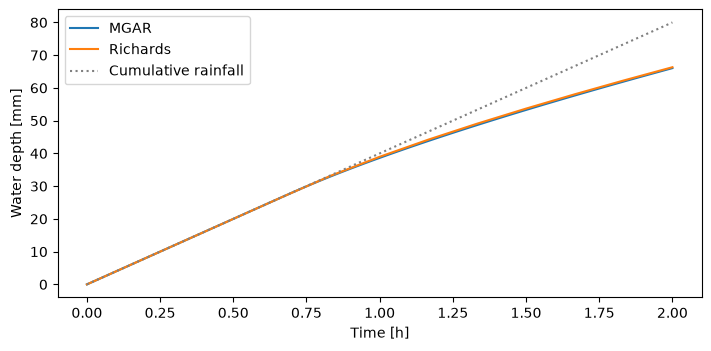

In [7]:
# Configure and run the baseline simulations, check water storage and plot cumulative infiltration.
soil = GOWDISH_SOILS["loam"].copy()
rain_hours, dry_hours = 2, 10
rain_end_s = 3600 * rain_hours
depth, dz, output_dt = 2.5, 0.01, 600
rain = np.r_[np.full(rain_hours, 40.), np.zeros(dry_hours)]
eta = 0.30

def run_richards(forcing, cell_size=dz, step_max=120., initial=None):
    return richards_gowdish_slope(
        rain=mmph_to_mps(forcing), Ks=soil["Ks_mps"],
        theta_r=soil["theta_r"], theta_s=soil["theta_s"],
        alpha_vg_cm=soil["alpha_cm"], n_vg=soil["n_vg"], m_vg=soil["m_vg"],
        ell_vg=soil["lambda_bc"], Se0=soil["Se0"], gamma_deg=0.,
        t_end=len(forcing)*3600, dt=output_dt, rain_mode="unsteady",
        rain_dt=3600., depth=depth, dz=cell_size,
        internal_dt_max=step_max, internal_dt_min=0.01, theta_initial=initial,
    )

def sample_index(run, seconds):
    index = int(np.searchsorted(run["t"], seconds))
    assert index < len(run["t"]) and run["t"][index] == seconds
    return index

def profile(snapshot, grid, smooth=False):
    fronts, drops = snapshot
    return mgar_profile_on_cells(fronts, drops, grid["z"], grid["dz"],
                                 soil["theta_i"], smooth=smooth, eta=eta)

mg = simulate_mgar_unsteady_slope(soil, 0., rain, dt=60.)
rich = run_richards(rain)
end_snapshot = mg["snapshots"][sample_index(mg, rain_end_s)]
initial = profile(end_snapshot, rich)
restart = run_richards(rain[rain_hours:], initial=initial)
assert mg["max_fronts"] == 1
assert rain[0]*rain_hours > 1000*max(mg["I"][-1], rich["I"][-1])
assert max(max(fronts, default=0.) for fronts, _ in mg["snapshots"]) < 1.
np.testing.assert_allclose(restart["theta"][0], initial, atol=1e-10, rtol=0)
np.testing.assert_allclose(sum(initial-soil["theta_i"])*rich["dz"],
                           mgar_storage_from_components(*end_snapshot), atol=1e-12, rtol=0)
for run in (rich, restart):
    assert np.max(np.abs(run["storage_error"]))*1000 < 0.05
    assert np.max(np.abs(run["theta"][:, -1]-soil["theta_i"])) < 0.005*soil["dtheta"]
print("Infiltration at the end of rainfall [mm]", round(1000*mg["I"][-1], 3), round(1000*rich["I"][-1], 3))
print("MGAR front depth at the end of rainfall [m]", round(end_snapshot[0][0], 4))
fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
for label, run in [("MGAR", mg), ("Richards", rich)]:
    wet = run["t"] <= rain_end_s
    ax.plot(run["t"][wet]/3600, run["I"][wet]*1000, label=label)
ax.plot([0, rain_hours], [0, rain[0]*rain_hours], ":", color="gray", label="Cumulative rainfall")
ax.set(xlabel="Time [h]", ylabel="Water depth [mm]")
ax.legend()
plt.show()

## Compare moisture profiles

How do MGAR and Richards differ at the end of rainfall and during redistribution? How does the answer change when Richards starts from the same moisture profile as MGAR? You should quantify differences in the upper metre and compare raw and smoothed MGAR profiles. Report the effect of smoothing on total water storage.

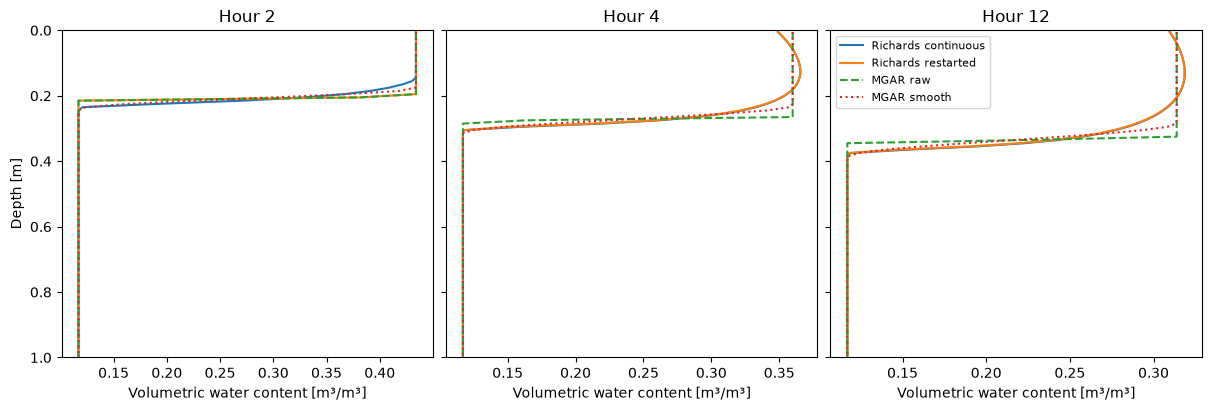

,hour,reference,MGAR,RMSE 0–1 m,mean difference 0–0.5 m,smoothing storage change [mm]
0,2,Richards continuous,raw,NaN,NaN,-1.495941e-05
1,2,Richards continuous,smooth,NaN,NaN,-1.495941e-05
2,2,Richards restarted,raw,NaN,NaN,-1.495941e-05
3,2,Richards restarted,smooth,NaN,NaN,-1.495941e-05
4,4,Richards continuous,raw,NaN,NaN,1.279254e-06
5,4,Richards continuous,smooth,NaN,NaN,1.279254e-06
6,4,Richards restarted,raw,NaN,NaN,1.279254e-06
7,4,Richards restarted,smooth,NaN,NaN,1.279254e-06
8,12,Richards continuous,raw,NaN,NaN,-3.352237e-07
9,12,Richards continuous,smooth,NaN,NaN,-3.352237e-07


In [8]:
# Plot baseline moisture profiles and provide a place to add comparison metrics.
def profile_metrics(candidate, reference, z):
    # TODO: Add profile error metrics.
    return np.nan, np.nan

rows = []
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, layout="constrained")
for ax, hour in zip(axes, [2, 4, 12]):
    seconds = hour*3600
    snapshot = mg["snapshots"][sample_index(mg, seconds)]
    raw, smooth = profile(snapshot, rich), profile(snapshot, rich, smooth=True)
    z = rich["z"]
    observations = {
        "Richards continuous": rich["theta"][sample_index(rich, seconds)],
        "Richards restarted": restart["theta"][sample_index(restart, seconds-rain_end_s)],
    }
    for label, values in observations.items():
        ax.plot(values, z, label=label)
        for name, candidate in [("raw", raw), ("smooth", smooth)]:
            rmse, delta_mean = profile_metrics(candidate, values, z)
            rows.append((hour, label, name, rmse, delta_mean, 1000*rich["dz"]*sum(smooth-raw)))
    ax.plot(raw, z, "--", label="MGAR raw")
    ax.plot(smooth, z, ":", label="MGAR smooth")
    ax.set(title=f"Hour {hour}", xlabel="Volumetric water content [m³/m³]", ylim=(1, 0))
axes[0].set_ylabel("Depth [m]")
axes[-1].legend(fontsize=8)
plt.show()
metrics = pd.DataFrame(rows, columns=["hour", "reference", "MGAR", "RMSE 0–1 m",
                                      "mean difference 0–0.5 m", "smoothing storage change [mm]"])
metrics

## Assess MGAR during rainfall

How sensitive are cumulative infiltration and wetting-front depth to the MGAR time step? You should quantify both errors against a justified numerical reference and explain what changes as you refine the time step.

In [10]:
# Expose the rainfall forcing for your time-step study.
rain_only = rain[:rain_hours]

# Add your rainfall accuracy study here.

## Assess MGAR during redistribution

theta goes from 0.434 to 0.3824 (FC = 0.2 so no clipping)
Z goes from 0.2083 to 0.2489 m


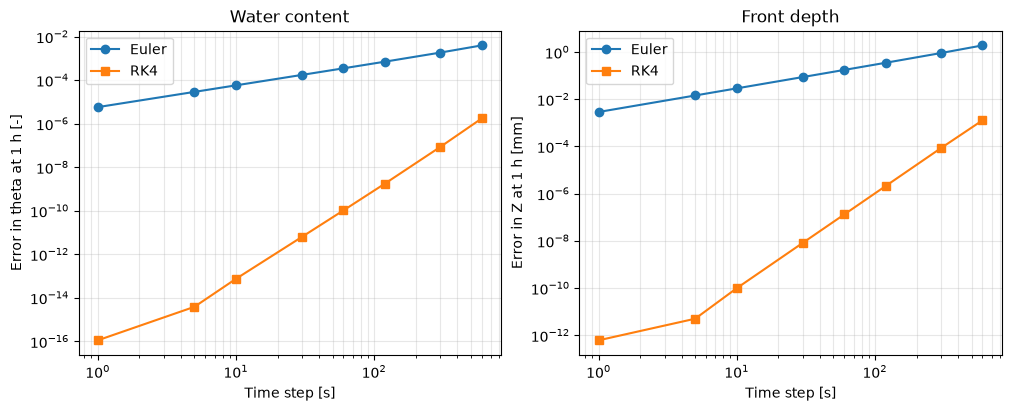

,dt [s],theta error Euler,theta error RK4,Z error Euler [mm],Z error RK4 [mm],RHS evals Euler,RHS evals RK4
0,600,0.003928,1.723841e-06,1.900819,1.273482e-03,6,24
1,300,0.001830,8.371641e-08,0.901564,8.435139e-05,12,48
2,120,0.000705,1.775474e-09,0.350979,2.132828e-06,30,120
3,60,0.000348,1.035267e-10,0.173998,1.317002e-07,60,240
4,30,0.000173,6.241174e-12,0.086635,8.168938e-09,120,480
5,10,0.000058,7.416290e-14,0.028799,9.886536e-11,360,1440
6,5,0.000029,3.830269e-15,0.014389,5.023759e-12,720,2880
7,1,0.000006,1.110223e-16,0.002876,6.106227e-13,3600,14400


In [11]:
theta_low = soil["theta_i"]
dry_initial = np.array([theta_low + end_snapshot[1][0], end_snapshot[0][0]])

def dry_rhs(state):
    theta, z = state
    drive = bc_K(theta, soil) + soil["Ks_mps"]*bc_G(theta_low, theta, soil)/z
    return np.array([(-bc_K(theta_low, soil)-drive)/z, drive/(theta-theta_low)])

def euler_step(state, dt):
    # y_{n+1} = y_n + dt f(y_n)
    return state + dt*dry_rhs(state)

def rk4_step(state, dt):
    return np.array(_redistribute_front_step_general(*state, dt, soil, theta_low, 0.))

def integrate_dry(step, dt, duration=3600):
    if duration % dt:
        raise ValueError("The duration must be a multiple of the time step.")
    states = np.empty((int(duration/dt)+1, 2))
    states[0] = dry_initial
    for k in range(1, len(states)):
        states[k] = step(states[k-1], dt)
    return states

# Reference solution: RK4 with a very small time step
ref = integrate_dry(rk4_step, 0.25)
print("theta goes from", round(ref[0, 0], 4), "to", round(ref[-1, 0], 4), "(FC =", soil["FC"], "so no clipping)")
print("Z goes from", round(ref[0, 1], 4), "to", round(ref[-1, 1], 4), "m")

steps = [600, 300, 120, 60, 30, 10, 5, 1]
results = []
for dt_dry in steps:
    eu = integrate_dry(euler_step, dt_dry)
    rk = integrate_dry(rk4_step, dt_dry)
    # errors at the end of the hour
    results.append([dt_dry,
                    abs(eu[-1, 0] - ref[-1, 0]), abs(rk[-1, 0] - ref[-1, 0]),
                    1000*abs(eu[-1, 1] - ref[-1, 1]), 1000*abs(rk[-1, 1] - ref[-1, 1]),
                    len(eu) - 1, 4*(len(rk) - 1)])

table = pd.DataFrame(results, columns=["dt [s]", "theta error Euler", "theta error RK4",
                                       "Z error Euler [mm]", "Z error RK4 [mm]",
                                       "RHS evals Euler", "RHS evals RK4"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].loglog(table["dt [s]"], table["theta error Euler"], "o-", label="Euler")
axes[0].loglog(table["dt [s]"], table["theta error RK4"], "s-", label="RK4")
axes[0].set(xlabel="Time step [s]", ylabel="Error in theta at 1 h [-]", title="Water content")
axes[1].loglog(table["dt [s]"], table["Z error Euler [mm]"], "o-", label="Euler")
axes[1].loglog(table["dt [s]"], table["Z error RK4 [mm]"], "s-", label="RK4")
axes[1].set(xlabel="Time step [s]", ylabel="Error in Z at 1 h [mm]", title="Front depth")
for ax in axes:
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)
plt.show()

table

## Check Richards as a numerical reference

You should assess how the spatial and temporal discretization affect the Richards results used in your comparison. Explain how much confidence your checks give you in the differences you report between the models.

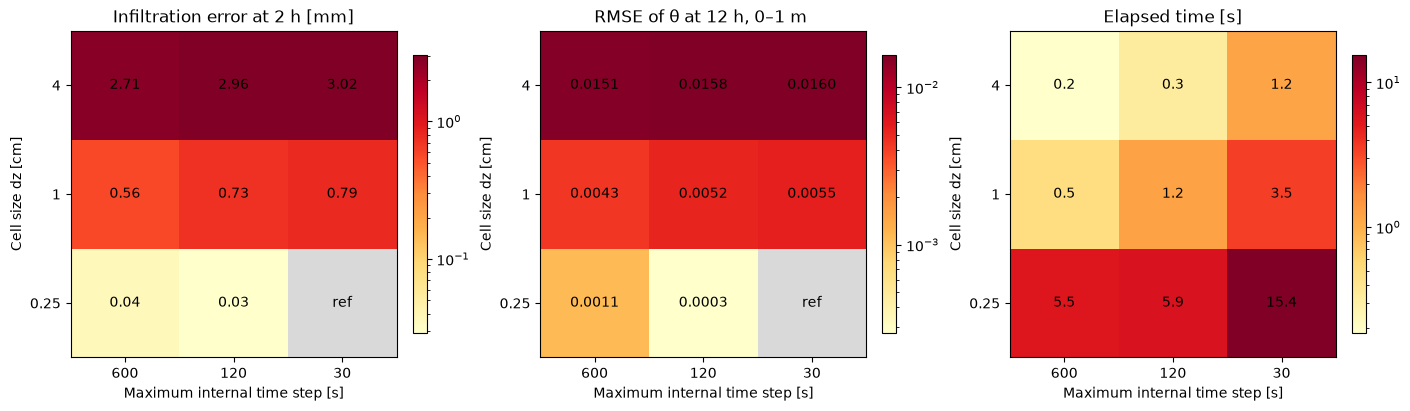

In [ ]:
# Richards sensitivity to the cell size dz and the maximum internal time step dt.
# Every (dz, dt) pair is compared with the finest run (dz = 0.25 cm, dt = 30 s).
import time
from matplotlib.colors import LogNorm

cells = [0.04, 0.01, 0.0025]    # cell size [m]
steps = [600., 120., 30.]       # maximum internal time step [s]

sweep = {}
for cell in cells:
    for step in steps:
        start = time.perf_counter()
        sweep[cell, step] = run_richards(rain, cell_size=cell, step_max=step)
        sweep[cell, step]["elapsed"] = time.perf_counter() - start
grid_runs = {cell: sweep[cell, 120.] for cell in cells}   # baseline time step, used again below
ref = sweep[cells[-1], steps[-1]]
k2 = sample_index(ref, rain_end_s)
upper = ref["z"] <= 1.0

I_err, rmse, elapsed = (np.zeros((len(cells), len(steps))) for _ in range(3))
for i, cell in enumerate(cells):
    for j, step in enumerate(steps):
        run = sweep[cell, step]
        I_err[i, j] = 1000*abs(run["I"][k2] - ref["I"][k2])
        theta_12h = np.interp(ref["z"], run["z"], run["theta"][-1])
        rmse[i, j] = np.sqrt(np.mean((theta_12h - ref["theta"][-1])[upper]**2))
        elapsed[i, j] = run["elapsed"]

panels = [(I_err, "Infiltration error at 2 h [mm]", "{:.2f}"),
          (rmse, "RMSE of θ at 12 h, 0–1 m ", "{:.4f}"),
          (elapsed, "Elapsed time [s]", "{:.1f}")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, (values, title, fmt) in zip(axes, panels):
    values = np.ma.masked_array(values, mask=(values == 0))
    image = ax.imshow(values, cmap="YlOrRd", norm=LogNorm(), aspect="auto")
    ax.set_facecolor("0.85")
    for i in range(len(cells)):
        for j in range(len(steps)):
            text = "ref" if values.mask[i, j] else fmt.format(values[i, j])
            ax.text(j, i, text, ha="center", va="center")
    ax.set_xticks(range(len(steps)), [f"{s:g}" for s in steps])
    ax.set_yticks(range(len(cells)), [f"{100*c:g}" for c in cells])
    ax.set(xlabel="Maximum internal time step [s]", ylabel="Cell size dz [cm]", title=title)
    fig.colorbar(image, ax=ax, shrink=0.85)
plt.show()

### Does Richards converge to MGAR as the grid is refined?

The maximum time step is fixed at 120 s, because the heatmaps show it has a negligible effect. The cell size goes from 4 cm down to 0.125 cm. Then we look at the MGAR gap, Richards(dz) against MGAR (after projecting it on the grrid), which goes to zero only if the two models give the same solution.

In [13]:
# Does Richards converge to MGAR when the grid is refined? (NO)
conv_runs = dict(grid_runs)
for cell in (0.005, 0.00125):
    conv_runs[cell] = run_richards(rain, cell_size=cell)
finest = conv_runs[0.00125]

I_mgar = 1000*mg["I"][sample_index(mg, rain_end_s)]
mgar_end = mg["snapshots"][-1]                        # MGAR state at 12 h

def rmse(a, b, z):
    return np.sqrt(np.mean((a - b)[z <= 1.0]**2))    # upper metre

rows = []
for cell in sorted(conv_runs, reverse=True):
    run = conv_runs[cell]
    I_rich = 1000*run["I"][sample_index(run, rain_end_s)]
    theta = run["theta"][-1]                          # Richards at 12 h
    rows.append([100*cell, I_rich, I_rich - I_mgar,
                 rmse(np.interp(finest["z"], run["z"], theta), finest["theta"][-1], finest["z"]),
                 rmse(profile(mgar_end, run), theta, run["z"])])

pd.DataFrame(rows, columns=["dz [cm]", " Richards at 2 h [mm]", " Richards - MGAR [mm]",
                            "RMSE 12 h vs fin Richards", "RMSE 12 h vs MGAR raw"]).round(4)

,dz [cm],Richards at 2 h [mm],Richards - MGAR [mm],RMSE 12 h vs fin Richards,RMSE 12 h vs MGAR raw
0,4.000,68.5544,2.5077,0.0163,0.0184
1,1.000,66.3220,0.2753,0.0060,0.0166
2,0.500,65.8023,-0.2445,0.0029,0.0173
3,0.250,65.5645,-0.4822,0.0010,0.0168
4,0.125,65.4728,-0.5740,0.0000,0.0168


## Compare computational cost

You should measure **elapsed solver time** for MGAR and Richards on the same rainfall and redistribution case. Distinguish rainfall from the full simulation. Report the ratio of Richards time to MGAR time and the percentage of time saved relative to Richards.

You should also quantify **numerical workload** separately. For MGAR, report time steps and right-hand-side evaluations during redistribution. For Richards, report grid cells, Picard iterations and rejected step attempts. Explain what the counts capture, describe how you obtained reliable measurements, and relate the measured speed difference to the accuracy observed at each configuration. If you include profile reconstruction, identify the time it adds.

In [14]:
def best_time(function, repeats=3):
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        result = function()
        times.append(time.perf_counter() - start)
    return min(times), result

rows = []
for case, forcing in [("rainfall (0-2 h)", rain[:rain_hours]), ("full (0-12 h)", rain)]:
    t_mg, run_mg = best_time(lambda: simulate_mgar_unsteady_slope(soil, 0., forcing, dt=60.))
    t_ri, run_ri = best_time(lambda: run_richards(forcing))
    dry_steps = np.sum(forcing == 0) * 3600 / run_mg["dt"]
    rows.append([case, t_mg, t_ri, t_ri/t_mg, 100*(1 - t_mg/t_ri),
                 len(run_mg["t"]) - 1, int(4*dry_steps*run_mg["max_fronts"]),
                 len(run_ri["z"]), run_ri["iterations"].sum(), run_ri["rejected_attempts"]])

display(pd.DataFrame(rows, columns=["case", "MGAR [s]", "Richards [s]", "Richards / MGAR", "time saved [%]",
                            "MGAR steps", "MGAR RHS evaluations",
                            "Richards cells", "Picard iterations", "rejected attempts"]).round(3))

,case,MGAR [s],Richards [s],Richards / MGAR,time saved [%],MGAR steps,MGAR RHS evaluations,Richards cells,Picard iterations,rejected attempts
0,rainfall (0-2 h),0.001,0.377,322.065,99.690,120,0,250,1965,2
1,full (0-12 h),0.040,1.184,29.385,96.597,720,2400,250,6007,2


## Reproducibility

State the settings and methods needed to reproduce your comparisons.